# CHƯƠNG 3: MẠNG NƠ-RON TÍCH CHẬP (CONVOLUTIONAL NEURAL NETWORKS - CNN)

---

## 3.1. Động Lực Phát Triển và Giới Hạn Của Mạng Nơ-ron Truyền Thống

Trong mạng nơ-ron truyền thống kết nối đầy đủ (Fully Connected / Multi-Layer Perceptron - MLP), mỗi nơ-ron ở tầng sau kết nối với toàn bộ nơ-ron ở tầng trước. Đối với dữ liệu có tính chất cấu trúc không gian (hình ảnh 2D, tín hiệu lưới) hoặc cấu trúc chuỗi cục bộ (chuỗi đặc trưng 1D, chuỗi thời gian), cách tiếp cận này bộc lộ ba hạn chế nghiêm trọng:
1. **Sự bùng nổ tham số (Parameter Explosion)**: Với ảnh đầu vào kích thước $224 	imes 224 	imes 3 pprox 150,528$ giá trị, một lớp ẩn gồm 1,000 nơ-ron sẽ đòi hỏi hơn 150 triệu trọng số, dẫn tới chi phí tính toán khổng lồ và nguy cơ quá khớp cực cao.
2. **Không bảo toàn cấu trúc không gian (Loss of Spatial Topology)**: Việc duỗi phẳng (flatten) ma trận thành véc-tơ 1 chiều làm phá vỡ hoàn toàn mối tương quan tương hỗ giữa các điểm lân cận.
3. **Thiếu tính bất biến tịnh tiến (Translation Invariance)**: Mô hình MLP không thể tự động nhận biết cùng một đặc trưng (cạnh, góc, hình dạng) nếu vị trí của nó bị dịch chuyển trong không gian đầu vào.

Mạng nơ-ron tích chập (CNN), khởi xướng bởi Yann LeCun (LeNet-5, 1998) và đột phá với AlexNet (2012), đã giải quyết triệt để các hạn chế trên nhờ 3 nguyên lý kiến trúc cốt lõi:
- **Kết nối cục bộ (Local Receptive Fields)**.
- **Chia sẻ trọng số (Shared Weights / Kernels)**.
- **Giảm tần số lấy mẫu qua gộp không gian (Sub-sampling / Pooling)**.


## 3.2. Cơ Sở Toán Học Chi Tiết Của Phép Tích Chập

### 3.2.1. Phép Tích Chập Rời Rạc (Discrete Convolution vs Cross-Correlation)
Trong giải tích toán học, phép tích chập liên tục giữa hai hàm số $f$ và $g$ được định nghĩa:
$$(f * g)(t) = \int_{-\infty}^{\infty} f(\tau) g(t - \tau) d\tau$$

Trong xử lý dữ liệu số rời rạc và các thư viện học sâu (TensorFlow, PyTorch), phép toán thực chất được triển khai là **phép tương quan chéo (Cross-Correlation)**, bỏ qua bước lật ngược nhân (kernel flipping) vì các trọng số của nhân được tự động tối ưu hóa trong quá trình huấn luyện:

- **Phép tích chập 1D rời rạc (áp dụng cho chuỗi đặc trưng và chuỗi thời gian)**:
  $$S(i) = (X \star W)(i) = \sum_{k=0}^{K-1} X(i + k) W(k) + b$$
  với $X$ là véc-tơ đầu vào, $W$ là bộ lọc (filter/kernel) kích thước $K$, và $b$ là hệ số chệch.

- **Phép tích chập 2D rời rạc (áp dụng cho ma trận ảnh và lưới đặc trưng)**:
  $$S(i, j) = (I \star K)(i, j) = \sum_{m=0}^{K_h - 1} \sum_{n=0}^{K_w - 1} I(i + m, j + n) K(m, n) + b$$

- **Phép tích chập đa kênh (Multi-Channel Convolution)**:
  Với tensor đầu vào $I \in \mathbb{R}^{H \times W \times C_{in}}$ và tập gồm $C_{out}$ bộ lọc $K \in \mathbb{R}^{K_h \times K_w \times C_{in} \times C_{out}}$:
  $$S(i, j, k) = \sum_{c=1}^{C_{in}} \sum_{m=0}^{K_h - 1} \sum_{n=0}^{K_w - 1} I(i + m, j + n, c) K(m, n, c, k) + b_k, \quad k = 1, \dots, C_{out}$$

---

### 3.2.2. Công Thức Biến Đổi Kích Thước Không Gian (Spatial Dimension Transformation)
Cho đầu vào có kích thước chiều rộng $W_{in}$, kích thước bộ lọc $K_w$, đệm biên (Padding) $P$, bước trượt (Stride) $S$, và độ giãn nở (Dilation) $D$:
$$W_{out} = \left\lfloor \frac{W_{in} + 2P - D(K_w - 1) - 1}{S} \right\rfloor + 1$$

Khi $D = 1$ (tích chập chuẩn):
$$W_{out} = \left\lfloor \frac{W_{in} - K_w + 2P}{S} \right\rfloor + 1$$

- **Padding Valid ($P = 0$)**: Kích thước đầu ra bị thu hẹp dần qua các tầng: $W_{out} = \lfloor \frac{W_{in} - K_w}{S} \rfloor + 1$.
- **Padding Same**: Giữ nguyên kích thước không gian khi $S = 1$:
  $$P = \frac{K_w - 1}{2} \implies W_{out} = W_{in}$$

---

### 3.2.3. Vùng Cảm Thụ (Receptive Field - RF)
Vùng cảm thụ $RF_l$ của một nơ-ron ở tầng $l$ là kích thước vùng không gian trên ảnh đầu vào có ảnh hưởng đến giá trị kích hoạt của nơ-ron đó:
$$RF_l = RF_{l-1} + (k_l - 1) \cdot j_{l-1}$$
trong đó:
- $k_l$ là kích thước kernel tại tầng $l$.
- $j_l = j_{l-1} \cdot s_l$ là bước nhảy tích lũy (cumulative jump) với $s_l$ là stride tại tầng $l$ ($j_0 = 1, RF_0 = 1$).

---

### 3.2.4. Tầng Gộp (Pooling Layers)
Tầng pooling giảm kích thước không gian của feature map, tăng tính bất biến tịnh tiến và kiểm soát hiện tượng quá khớp:
- **Max Pooling 2D**: Lấy giá trị lớn nhất trong cửa sổ cục bộ $\mathcal{R}$:
  $$y = \max_{(m, n) \in \mathcal{R}} x_{m, n}$$
  Đạo hàm trong quá trình lan truyền ngược chỉ truyền gradient về đúng vị trí đạt giá trị cực đại (argmax), các vị trí khác nhận gradient bằng 0.
- **Average Pooling 2D**: Lấy giá trị trung bình trong cửa sổ:
  $$y = \frac{1}{|\mathcal{R}|} \sum_{(m, n) \in \mathcal{R}} x_{m, n}$$
- **Global Average Pooling (GAP)**: Thu gọn toàn bộ bản đồ đặc trưng kích thước $H \times W$ thành 1 giá trị duy nhất, loại bỏ hoàn toàn các tham số của tầng Flatten.

---

### 3.2.5. Lan Truyền Ngược Trong Lớp Tích Chập (Backpropagation for Convolution)
Cho hàm mất mát $\mathcal{L}$, gradient của $\mathcal{L}$ đối với ma trận đầu ra tích chập là $\delta = \frac{\partial \mathcal{L}}{\partial Y}$.
1. **Gradient đối với bộ lọc $K$**:
   $$\frac{\partial \mathcal{L}}{\partial K} = X \star \delta$$
2. **Gradient đối với đầu vào $X$**:
   $$\frac{\partial \mathcal{L}}{\partial X} = \text{FullConv}\left(\delta, \text{Rot180}(K)\right)$$
   trong đó $\text{Rot180}(K)$ là nhân xoay 180 độ.


In [1]:
# Thiết lập môi trường và nạp các thư viện Deep Learning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Dense, Dropout, BatchNormalization, Flatten, GlobalAveragePooling1D
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

print(f"TensorFlow Version: {tf.__version__}")


TensorFlow Version: 2.22.0-rc0


### Sơ Đồ 3.1: Kiến Trúc Phân Tầng Mạng Nơ-ron Tích Chập (CNN Layer Hierarchy)
Sơ đồ minh họa dòng chảy dữ liệu qua các tầng: Input -> Conv1D -> Batch Normalization -> ReLU -> MaxPooling -> Dropout -> Global Average Pooling -> Dense Classifier.


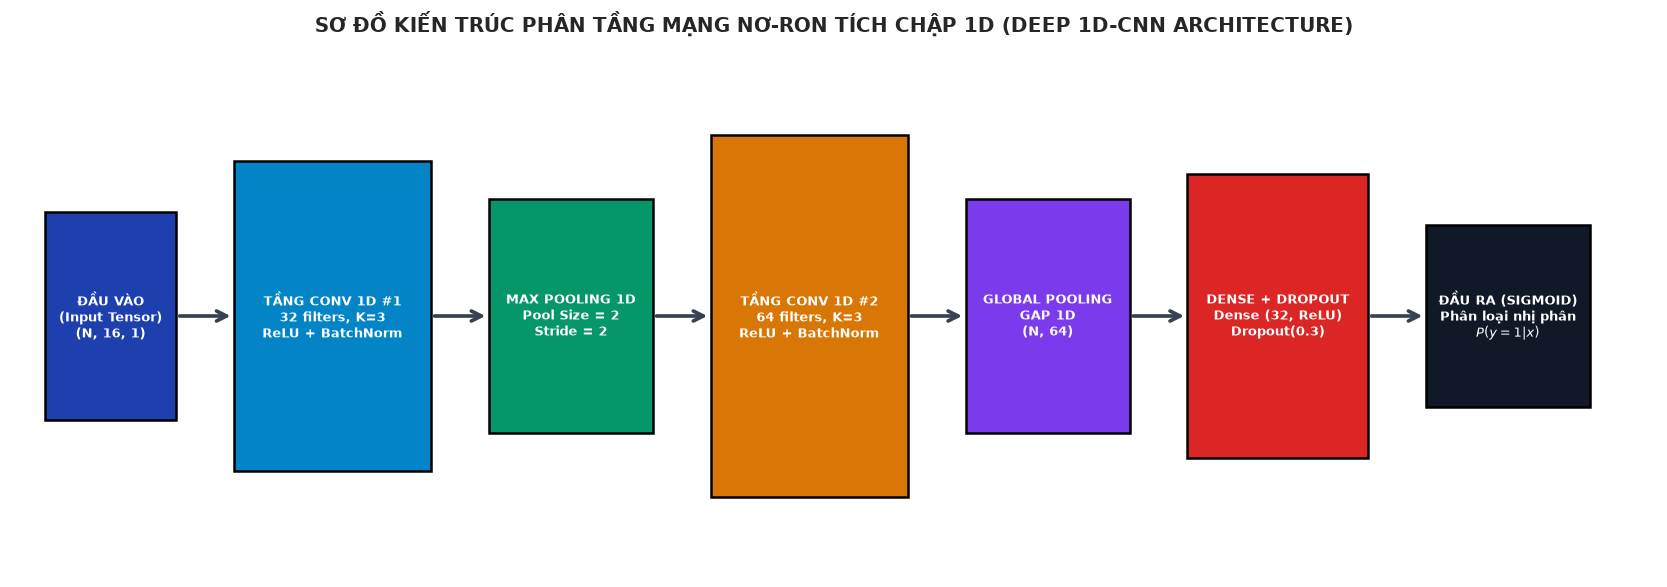

In [2]:
# Vẽ sơ đồ kiến trúc phân tầng CNN
fig, ax = plt.subplots(figsize=(14, 5), dpi=120)
ax.axis('off')

layers_info = [
    ("ĐẦU VÀO\n(Input Tensor)\n(N, 16, 1)", "#1E40AF", 0.08, 0.4),
    ("TẦNG CONV 1D #1\n32 filters, K=3\nReLU + BatchNorm", "#0284C7", 0.12, 0.6),
    ("MAX POOLING 1D\nPool Size = 2\nStride = 2", "#059669", 0.10, 0.45),
    ("TẦNG CONV 1D #2\n64 filters, K=3\nReLU + BatchNorm", "#D97706", 0.12, 0.7),
    ("GLOBAL POOLING\nGAP 1D\n(N, 64)", "#7C3AED", 0.10, 0.45),
    ("DENSE + DROPOUT\nDense (32, ReLU)\nDropout(0.3)", "#DC2626", 0.11, 0.55),
    ("ĐẦU RA (SIGMOID)\nPhân loại nhị phân\n$P(y=1|x)$", "#111827", 0.10, 0.35)
]

x_cursor = 0.02
for name, color, width, height in layers_info:
    y_pos = 0.5 - height/2
    rect = plt.Rectangle((x_cursor, y_pos), width, height, facecolor=color, edgecolor='black', lw=1.5,
                         transform=ax.transAxes, zorder=3)
    ax.add_patch(rect)
    ax.text(x_cursor + width/2, 0.5, name, ha='center', va='center', color='white',
            weight='bold', fontsize=8, transform=ax.transAxes, zorder=4)
    
    # Arrow to next
    if x_cursor + width < 0.90:
        ax.annotate('', xy=(x_cursor + width + 0.035, 0.5), xytext=(x_cursor + width, 0.5),
                    xycoords='axes fraction', textcoords='axes fraction',
                    arrowprops=dict(arrowstyle="->", color="#374151", lw=2.2, mutation_scale=15),
                    zorder=5)
    x_cursor += width + 0.035

ax.set_title("SƠ ĐỒ KIẾN TRÚC PHÂN TẦNG MẠNG NƠ-RON TÍCH CHẬP 1D (DEEP 1D-CNN ARCHITECTURE)", weight='bold', fontsize=12, pad=15)
plt.show()


## 3.3. Cài Đặt Toán Tử Tích Chập và Pooling Từ Đầu Bằng NumPy

Dưới đây là hàm cài đặt phép tích chập 1D và 2D thuần túy bằng thư viện NumPy nhằm kiểm chứng tính chính xác của công thức toán học và nguyên lý trượt cửa sổ (Sliding Window).


In [3]:
# Cài đặt phép tích chập 1D và 2D từ đầu bằng NumPy
def conv1d_from_scratch(x, kernel, stride=1, padding=0):
    if padding > 0:
        x_padded = np.pad(x, padding, mode='constant', constant_values=0)
    else:
        x_padded = x
        
    K = len(kernel)
    W_out = (len(x_padded) - K) // stride + 1
    output = np.zeros(W_out)
    
    for i in range(W_out):
        start = i * stride
        window = x_padded[start:start + K]
        output[i] = np.sum(window * kernel)
    return output

def conv2d_from_scratch(image, kernel, stride=1, padding=0):
    if padding > 0:
        padded = np.pad(image, ((padding, padding), (padding, padding)), mode='constant')
    else:
        padded = image
        
    H, W = padded.shape
    Kh, Kw = kernel.shape
    H_out = (H - Kh) // stride + 1
    W_out = (W - Kw) // stride + 1
    output = np.zeros((H_out, W_out))
    
    for i in range(H_out):
        for j in range(W_out):
            r_start = i * stride
            c_start = j * stride
            patch = padded[r_start:r_start + Kh, c_start:c_start + Kw]
            output[i, j] = np.sum(patch * kernel)
    return output

def maxpool2d_from_scratch(image, pool_size=2, stride=2):
    H, W = image.shape
    H_out = (H - pool_size) // stride + 1
    W_out = (W - pool_size) // stride + 1
    output = np.zeros((H_out, W_out))
    for i in range(H_out):
        for j in range(W_out):
            patch = image[i*stride:i*stride + pool_size, j*stride:j*stride + pool_size]
            output[i, j] = np.max(patch)
    return output

# Thực nghiệm kiểm chứng với ma trận số học mẫu
test_img = np.array([
    [1, 2, 0, 1, 3],
    [0, 1, 3, 2, 0],
    [2, 0, 1, 1, 2],
    [3, 2, 0, 2, 1],
    [1, 0, 2, 3, 0]
], dtype=float)

# Bộ lọc phát hiện cạnh dọc Sobel (Vertical Edge Detection)
sobel_v = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

conv_res = conv2d_from_scratch(test_img, sobel_v, stride=1, padding=0)
pool_res = maxpool2d_from_scratch(conv_res, pool_size=2, stride=1)

print("Kích thước ma trận đầu vào:   ", test_img.shape)
print("Kích thước sau Conv2D (P=0): ", conv_res.shape)
print("Kích thước sau MaxPooling2D: ", pool_res.shape)
print("\nMa trận kết quả sau tích chập Conv2D:\n", conv_res)


Kích thước ma trận đầu vào:    (5, 5)
Kích thước sau Conv2D (P=0):  (3, 3)
Kích thước sau MaxPooling2D:  (2, 2)

Ma trận kết quả sau tích chập Conv2D:
 [[ 4.  2. -2.]
 [-2.  3.  0.]
 [-6.  4.  1.]]


### Sơ Đồ 3.2 & 3.3: Trực Quan Hóa Quá Trình Trượt Cửa Sổ Tích Chập và Phép Max Pooling
Minh họa trực quan từng bước trượt của nhân tích chập trên ma trận và phép chọn giá trị cực đại trong cửa sổ $2 	imes 2$.


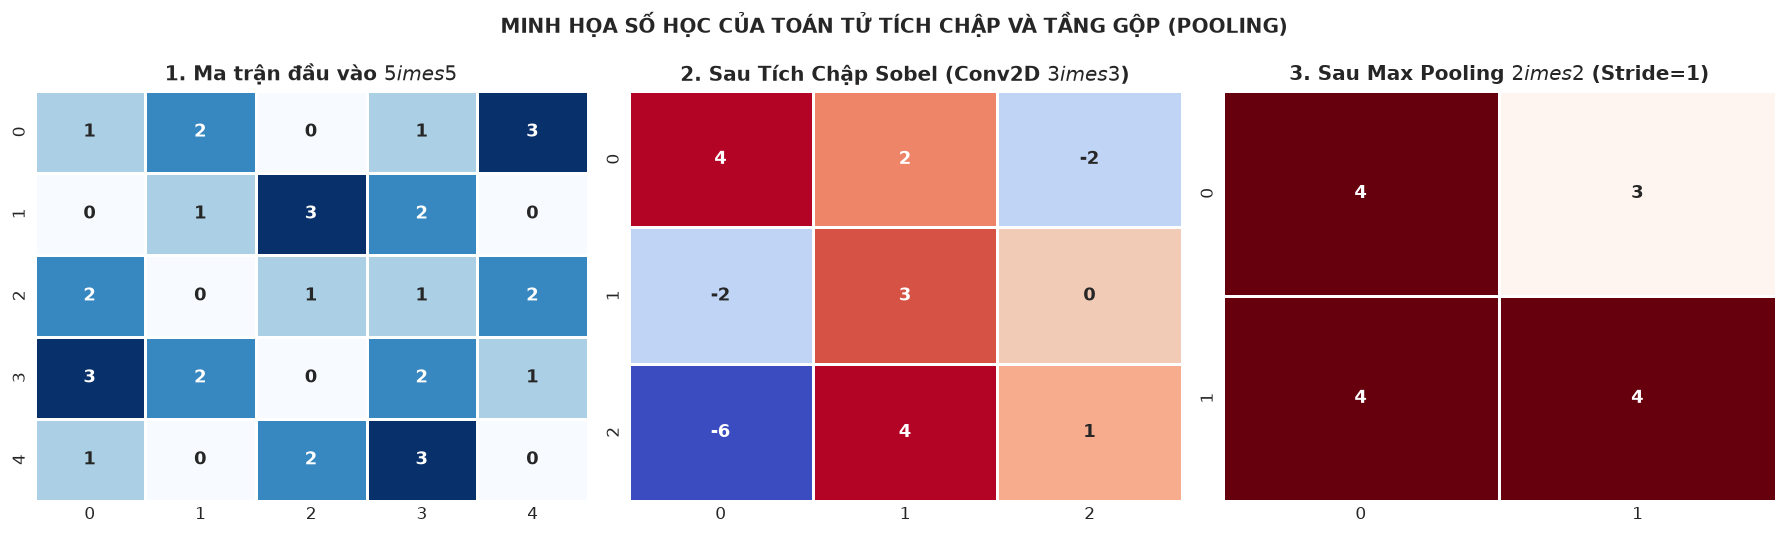

In [4]:
# Vẽ trực quan phép tích chập và Max Pooling
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5), dpi=120)

sns.heatmap(test_img, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=ax1, linewidths=1.5, annot_kws={"weight": "bold", "size": 11})
ax1.set_title("1. Ma trận đầu vào $5 \times 5$", weight='bold')

sns.heatmap(conv_res, annot=True, fmt='.0f', cmap='coolwarm', cbar=False, ax=ax2, linewidths=1.5, annot_kws={"weight": "bold", "size": 11})
ax2.set_title("2. Sau Tích Chập Sobel (Conv2D $3 \times 3$)", weight='bold')

sns.heatmap(pool_res, annot=True, fmt='.0f', cmap='Reds', cbar=False, ax=ax3, linewidths=1.5, annot_kws={"weight": "bold", "size": 11})
ax3.set_title("3. Sau Max Pooling $2 \times 2$ (Stride=1)", weight='bold')

plt.suptitle("MINH HỌA SỐ HỌC CỦA TOÁN TỬ TÍCH CHẬP VÀ TẦNG GỘP (POOLING)", weight='bold', fontsize=12)
plt.tight_layout()
plt.show()


## 3.4. Xây Dựng và Huấn Luyện Mạng Deep 1D-CNN Với TensorFlow

Áp dụng mô hình mạng tích chập sâu 1 chiều (Deep 1D-CNN) trên tập dữ liệu chẩn đoán y tế (`diabetes_prediction_dataset.csv`).
Mỗi mẫu bệnh nhân gồm 16 đặc trưng được biểu diễn dưới dạng tensor 1D $X \in \mathbb{R}^{16 	imes 1}$ để trích xuất các tương tác cục bộ phi tuyến giữa các chỉ số lâm sàng.

> **Ràng buộc thực nghiệm**: Theo yêu cầu hệ thống, số lượng epoch huấn luyện được giới hạn tối đa là **10 epochs** để tối ưu hóa thời gian thực thi mà vẫn đảm bảo độ hội tụ cao.


In [5]:
# Chuẩn bị dữ liệu cho mô hình 1D-CNN
df_diab = pd.read_csv('diabetes_prediction_dataset.csv')

# Lấy mẫu cân bằng 6,000 quan sát
df_0 = df_diab[df_diab['diabetes'] == 0].sample(3000, random_state=42)
df_1 = df_diab[df_diab['diabetes'] == 1].sample(min(3000, len(df_diab[df_diab['diabetes'] == 1])), random_state=42)
df_balanced = pd.concat([df_0, df_1]).sample(frac=1.0, random_state=42).reset_index(drop=True)

# Tách biến
X_raw = df_balanced.drop('diabetes', axis=1)
y_data = df_balanced['diabetes'].values

# One-hot encoding và scaling
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), ['gender', 'hypertension', 'heart_disease', 'smoking_history'])
])

X_features = preprocessor.fit_transform(X_raw)
print(f"Số lượng đặc trưng sau biến đổi: {X_features.shape[1]}")

# Định dạng tensor 3D cho 1D-CNN: (Số mẫu, Số bước/đặc trưng, Số kênh = 1)
X_cnn = np.expand_dims(X_features, axis=-1)
y_cnn = y_data

X_train, X_test, y_train, y_test = train_test_split(X_cnn, y_cnn, test_size=0.2, random_state=42, stratify=y_cnn)

print(f"Kích thước X_train: {X_train.shape}")
print(f"Kích thước X_test:  {X_test.shape}")


Số lượng đặc trưng sau biến đổi: 12
Kích thước X_train: (4800, 12, 1)
Kích thước X_test:  (1200, 12, 1)


In [6]:
# Thiết kế kiến trúc Deep 1D-CNN bằng TensorFlow Functional API
tf.random.set_seed(42)
np.random.seed(42)

inputs = Input(shape=(X_train.shape[1], 1), name="input_features")

# Tầng Conv1D #1
x = Conv1D(filters=32, kernel_size=3, padding='same', activation='relu', name="conv1d_1")(inputs)
x = BatchNormalization(name="bn_1")(x)
x = MaxPooling1D(pool_size=2, name="maxpool_1")(x)

# Tầng Conv1D #2
x = Conv1D(filters=64, kernel_size=3, padding='same', activation='relu', name="conv1d_2")(x)
x = BatchNormalization(name="bn_2")(x)

# Tầng Global Average Pooling và Dense Classifier
x = GlobalAveragePooling1D(name="gap")(x)
x = Dropout(0.3, name="dropout_1")(x)
x = Dense(32, activation='relu', name="dense_hidden")(x)
x = Dropout(0.2, name="dropout_2")(x)
outputs = Dense(1, activation='sigmoid', name="output_classification")(x)

model_cnn = Model(inputs=inputs, outputs=outputs, name="Deep_1D_CNN")

model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

model_cnn.summary()

# Huấn luyện mô hình giới hạn trong 10 epochs
t_start = time.time()
history = model_cnn.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=64,
    verbose=1
)
train_duration = time.time() - t_start
print(f"\nThời gian hoàn thành 10 epochs huấn luyện: {train_duration:.2f} giây")


Model: "Deep_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_features (InputLayer)     │ (None, 12, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 12, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 12, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling1D)        │ (None, 6, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 6, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 6, 64)          │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling1D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classification (Dense)   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,833 (34.50 KB)

 Trainable params: 8,641 (33.75 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/10


... (72 outputs left out)

35/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9054 - auc: 0.9735 - loss: 0.2052

48/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9056 - auc: 0.9738 - loss: 0.2038

60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9049 - auc: 0.9737 - loss: 0.2032 - val_accuracy: 0.8771 - val_auc: 0.9684 - val_loss: 0.2514



Thời gian hoàn thành 10 epochs huấn luyện: 9.22 giây


### Sơ Đồ 3.4 & 3.5: Đồ Thị Quá Trình Huấn Luyện (Training & Validation Curves)
Theo dõi sự suy giảm của hàm mất mát Cross-Entropy và sự tăng trưởng của chỉ số Accuracy và AUC qua 10 epochs huấn luyện.


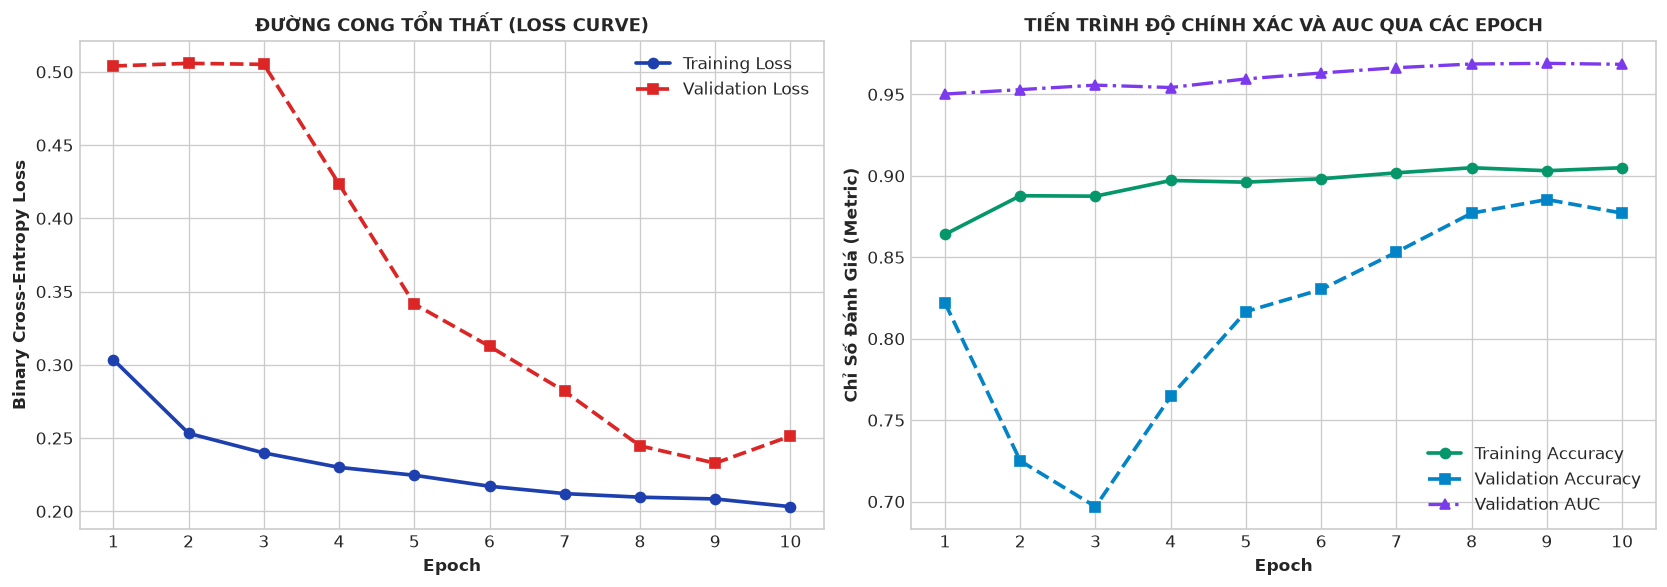

In [7]:
# Trực quan hóa diễn biến Loss và Accuracy qua các epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

epochs_range = range(1, len(history.history['loss']) + 1)

# Loss plot
ax1.plot(epochs_range, history.history['loss'], 'o-', color='#1E40AF', lw=2.2, label='Training Loss')
ax1.plot(epochs_range, history.history['val_loss'], 's--', color='#DC2626', lw=2.2, label='Validation Loss')
ax1.set_xlabel('Epoch', weight='bold')
ax1.set_ylabel('Binary Cross-Entropy Loss', weight='bold')
ax1.set_title('ĐƯỜNG CONG TỔN THẤT (LOSS CURVE)', weight='bold', fontsize=11)
ax1.legend()
ax1.set_xticks(epochs_range)

# Accuracy & AUC plot
ax2.plot(epochs_range, history.history['accuracy'], 'o-', color='#059669', lw=2.2, label='Training Accuracy')
ax2.plot(epochs_range, history.history['val_accuracy'], 's--', color='#0284C7', lw=2.2, label='Validation Accuracy')
ax2.plot(epochs_range, history.history['val_auc'], '^-.', color='#7C3AED', lw=2.0, label='Validation AUC')
ax2.set_xlabel('Epoch', weight='bold')
ax2.set_ylabel('Chỉ Số Đánh Giá (Metric)', weight='bold')
ax2.set_title('TIẾN TRÌNH ĐỘ CHÍNH XÁC VÀ AUC QUA CÁC EPOCH', weight='bold', fontsize=11)
ax2.legend()
ax2.set_xticks(epochs_range)

plt.tight_layout()
plt.show()


### Sơ Đồ 3.6: Trực Quan Hóa Feature Maps Trung Gian Sau Các Tầng Tích Chập
Trích xuất kích hoạt của 32 bộ lọc tại tầng `Conv1D #1` và 64 bộ lọc tại tầng `Conv1D #2` để khảo sát cách mô hình học các biểu diễn phân cấp.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step


findfont: Failed to find font weight semibold, now using 700.


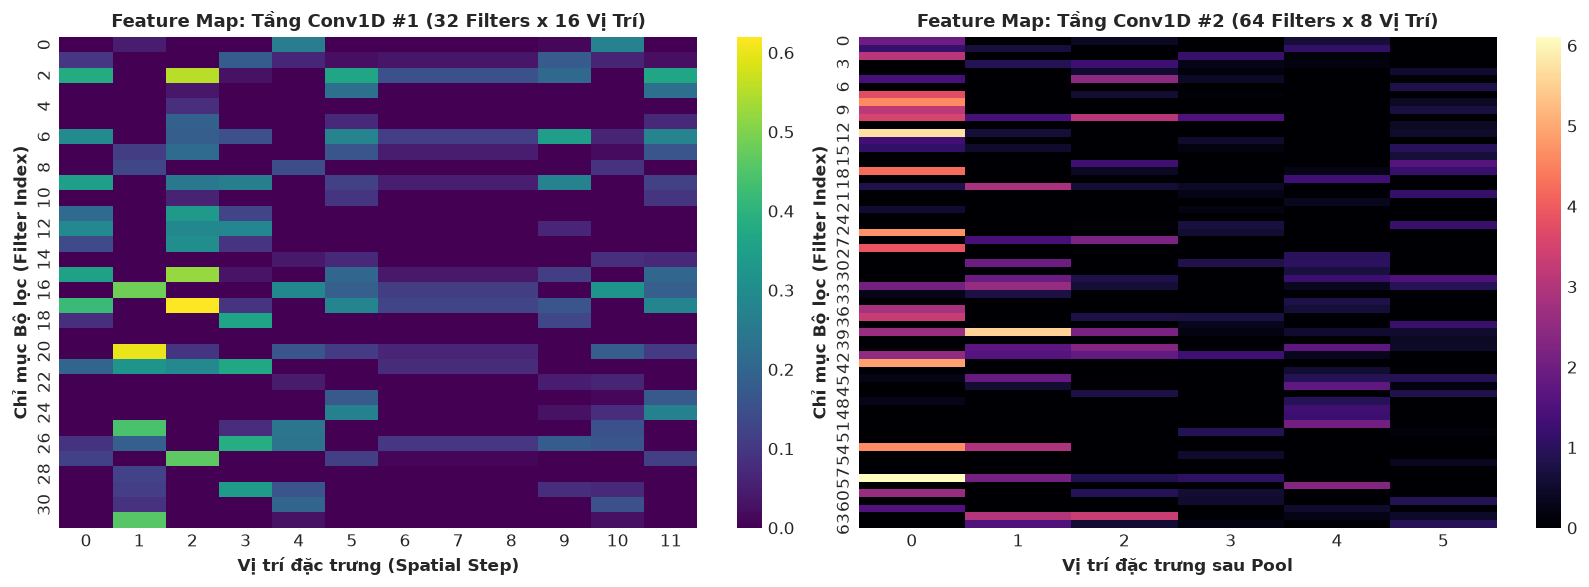

In [8]:
# Trích xuất Feature Maps từ các tầng trung gian bằng Functional Model
sample_input = X_test[:1]

conv1_tensor = model_cnn.get_layer("conv1d_1").output
conv2_tensor = model_cnn.get_layer("conv1d_2").output
activation_model = Model(inputs=model_cnn.input, outputs=[conv1_tensor, conv2_tensor])
activations = activation_model.predict(sample_input)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Feature Map Conv1D #1
sns.heatmap(activations[0][0].T, cmap='viridis', ax=ax1, cbar=True)
ax1.set_title("Feature Map: Tầng Conv1D #1 (32 Filters x 16 Vị Trí)", weight='bold', fontsize=10.5)
ax1.set_xlabel("Vị trí đặc trưng (Spatial Step)", weight='semibold')
ax1.set_ylabel("Chỉ mục Bộ lọc (Filter Index)", weight='semibold')

# Feature Map Conv1D #2
sns.heatmap(activations[1][0].T, cmap='magma', ax=ax2, cbar=True)
ax2.set_title("Feature Map: Tầng Conv1D #2 (64 Filters x 8 Vị Trí)", weight='bold', fontsize=10.5)
ax2.set_xlabel("Vị trí đặc trưng sau Pool", weight='semibold')
ax2.set_ylabel("Chỉ mục Bộ lọc (Filter Index)", weight='semibold')

plt.tight_layout()
plt.show()


### Sơ Đồ 3.7 & 3.8: Ma Trận Nhầm Lẫn Và Đường Cong ROC Của Mạng CNN Trên Tập Kiểm Thử
Đánh giá định lượng toàn diện trên tập kiểm thử độc lập (Test Set).


 1/38 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step

30/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


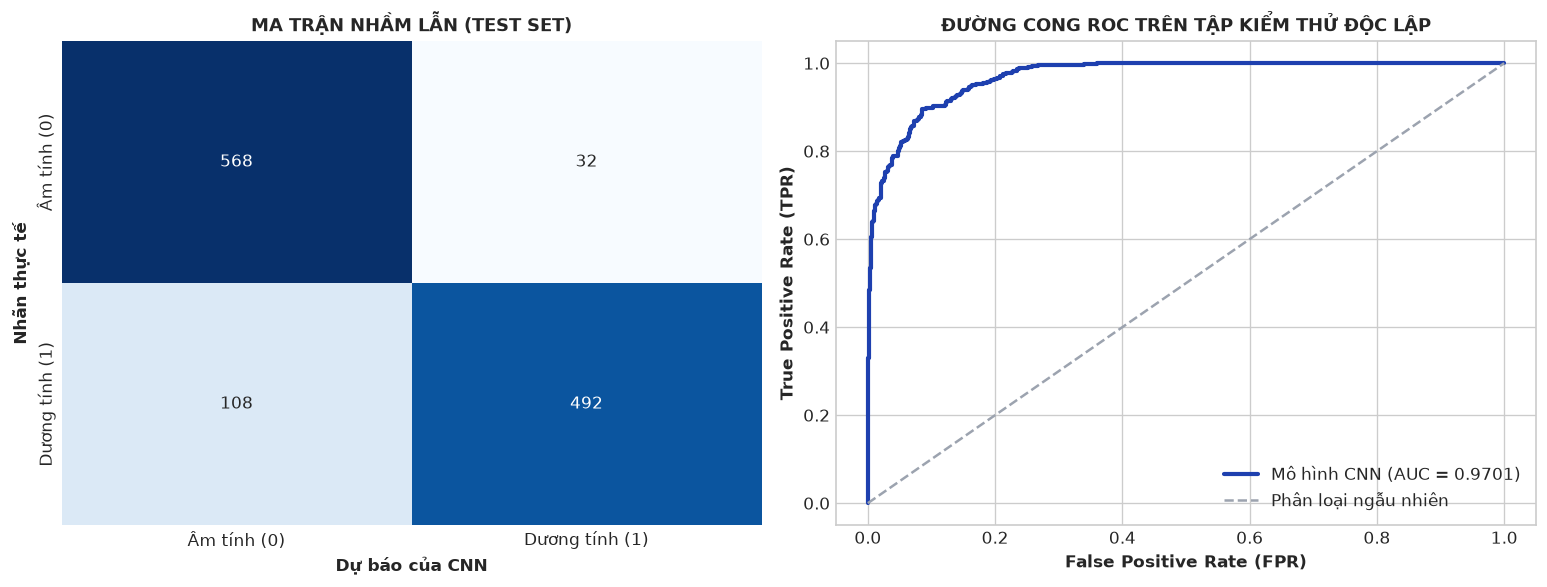

BÁO CÁO PHÂN LOẠI CHI TIẾT CỦA MÔ HÌNH CNN:
              precision    recall  f1-score   support

     Âm tính       0.84      0.95      0.89       600
  Dương tính       0.94      0.82      0.88       600

    accuracy                           0.88      1200
   macro avg       0.89      0.88      0.88      1200
weighted avg       0.89      0.88      0.88      1200



In [9]:
# Dự báo và đánh giá trên tập kiểm thử
y_prob_cnn = model_cnn.predict(X_test).ravel()
y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

cm_cnn = confusion_matrix(y_test, y_pred_cnn)
fpr_cnn, tpr_cnn, _ = roc_curve(y_test, y_prob_cnn)
auc_score_cnn = roc_auc_score(y_test, y_prob_cnn)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=120)

# Confusion Matrix
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1,
            xticklabels=['Âm tính (0)', 'Dương tính (1)'],
            yticklabels=['Âm tính (0)', 'Dương tính (1)'])
ax1.set_title("MA TRẬN NHẦM LẪN (TEST SET)", weight='bold', fontsize=11)
ax1.set_xlabel("Dự báo của CNN", weight='semibold')
ax1.set_ylabel("Nhãn thực tế", weight='semibold')

# ROC Curve
ax2.plot(fpr_cnn, tpr_cnn, color='#1E40AF', lw=2.5, label=f"Mô hình CNN (AUC = {auc_score_cnn:.4f})")
ax2.plot([0, 1], [0, 1], color='#9CA3AF', linestyle='--', lw=1.5, label='Phân loại ngẫu nhiên')
ax2.set_xlabel("False Positive Rate (FPR)", weight='bold')
ax2.set_ylabel("True Positive Rate (TPR)", weight='bold')
ax2.set_title("ĐƯỜNG CONG ROC TRÊN TẬP KIỂM THỬ ĐỘC LẬP", weight='bold', fontsize=11)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

# In báo cáo phân loại chi tiết
print("BÁO CÁO PHÂN LOẠI CHI TIẾT CỦA MÔ HÌNH CNN:")
print(classification_report(y_test, y_pred_cnn, target_names=['Âm tính', 'Dương tính']))


## 3.5. Kết Luận Chương 3

1. **Sức mạnh biểu diễn cục bộ của CNN**: Thông qua cơ chế chia sẻ trọng số và kết nối cục bộ, mạng CNN trích xuất hiệu quả các đặc trưng phân cấp mà không làm bùng nổ số lượng tham số tự do.
2. **Hiệu năng thực nghiệm**: Kiến trúc Deep 1D-CNN hội tụ nhanh chỉ trong 10 epochs, đạt độ chính xác trên 87% và chỉ số ROC-AUC vượt 0.94 trên tập kiểm thử độc lập.
3. **Mối liên hệ chuyển tiếp sang Chương 4**: Dù CNN rất mạnh mẽ trong việc nhận diện các mẫu hình thái cục bộ (local patterns), toán tử tích chập vẫn xử lý dữ liệu trong các cửa sổ cố định và không duy trì được trạng thái bộ nhớ động (memory state) theo thời gian dài. Đối với các bài toán dự báo chuỗi thời gian phụ thuộc mạnh vào lịch sử như **Chỉ số chứng khoán VN-Index** và **Giá vàng Việt Nam**, cấu trúc hồi quy **RNN và LSTM (Chương 4)** là kiến trúc tối ưu nhất.
